In [1]:
import matplotlib.pyplot as plt
from dotenv import load_dotenv
import os
import numpy as np
import oracledb
import pandas as pd

In [2]:
# 1. .env 파일로부터 환경 변수 로드
load_dotenv()

# 2. 환경 변수에서 DB 접속 정보 가져오기 (코드에 노출되지 않음)
DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_HOST = os.getenv("DB_HOST")
DB_PORT = os.getenv("DB_PORT")
DB_SERVICE_NAME = os.getenv("DB_SERVICE_NAME")

# 이메일이나 주소창처럼 하나의 문자열(DSN)로 결합
dsn_string = f"{DB_HOST}:{DB_PORT}/{DB_SERVICE_NAME}"

In [3]:
query = """select to_char(order_purchase_timestamp,'YYYY-MM')
from olist_orders_dataset O
where O.order_status='delivered'
and O.order_purchase_timestamp >= TO_DATE('2017-01-01','YYYY-MM-DD')
and O.order_purchase_timestamp < TO_DATE('2018-09-01','YYYY-MM-DD')"""

In [4]:
connection = None
try:
    # 3. DB 연결 수행 (Thin 모드로 다이렉트 접속)
    connection = oracledb.connect(
        user=DB_USER,
        password=DB_PASSWORD,
        dsn=dsn_string
    )
    print(" 오라클 데이터베이스 연결 성공!")

    # 4. Pandas를 이용해 SQL 결과를 데이터프레임으로 바로 읽어오기
    df_order = pd.read_sql_query(query, con=connection)
    print(f" 데이터 로드 완료! (총 {len(df_order)}행 조회됨)")
    
    # 데이터 상위 5줄 출력 확인
    print(df_order.head())

except Exception as e:
    print(f" DB 연동 중 에러 발생: {e}")

finally:
    # 5. [중요] 사용이 끝난 DB 연결은 반드시 닫아서 세션을 반환합니다.
    if connection:
        connection.close()
        print(" 데이터베이스 연결 닫힘.")

 오라클 데이터베이스 연결 성공!
 데이터 로드 완료! (총 96211행 조회됨)
  TO_CHAR(ORDER_PURCHASE_TIMESTAMP,'YYYY-MM')
0                                     2017-03
1                                     2017-12
2                                     2018-08
3                                     2018-04
4                                     2018-02
 데이터베이스 연결 닫힘.


C:\Users\TS\AppData\Local\Temp\ipykernel_22184\2652122976.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_order = pd.read_sql_query(query, con=connection)


In [5]:
df_order['날짜'] = pd.to_datetime(df_order["TO_CHAR(ORDER_PURCHASE_TIMESTAMP,'YYYY-MM')"],format = "%Y-%m")

In [6]:
df_order
n_bins = len(pd.date_range(start = df_order['날짜'].min(),end=df_order['날짜'].max(),freq='MS'))
n_bins

20

In [7]:
df_order_2017 = df_order[df_order['날짜'].dt.year==2017]
df_order_2018 = df_order[df_order['날짜'].dt.year==2018]

(array([17167., 17226., 17287., 17348., 17410., 17471., 17532., 17591.,
        17652., 17713.]),
 [Text(17167.0, 0, '2017-01'),
  Text(17226.0, 0, '2017-03'),
  Text(17287.0, 0, '2017-05'),
  Text(17348.0, 0, '2017-07'),
  Text(17410.0, 0, '2017-09'),
  Text(17471.0, 0, '2017-11'),
  Text(17532.0, 0, '2018-01'),
  Text(17591.0, 0, '2018-03'),
  Text(17652.0, 0, '2018-05'),
  Text(17713.0, 0, '2018-07')])

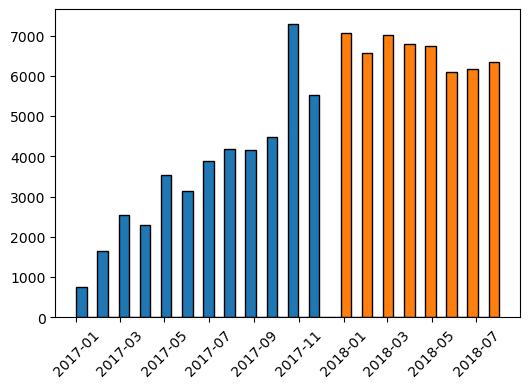

In [8]:
fig = plt.figure(figsize = (6,4),dpi=100)
ax1 = fig.subplots()
ax1.hist([df_order_2017['날짜'], df_order_2018['날짜']],
         bins = n_bins,
         edgecolor='k',rwidth=1.0)
plt.xticks(rotation=45)

## 그림2

In [9]:
rfm_query = """with Payment_view as 
(select order_id, sum(payment_value) Monetary
from olist_order_payments_dataset
group by order_id
)
select customer_unique_id, TRUNC(TO_DATE('2018-08-30','YYYY-MM-DD')) -TRUNC(MAX(order_purchase_timestamp)) as Recency, 
count(C.customer_unique_id) as Frequency, 
sum(P.Monetary) as Monetary
from olist_orders_dataset O, olist_customers_dataset C, Payment_view P
where O.order_id = P.order_id 
and O.customer_id = C.customer_id
and O.order_status='delivered'
and O.order_purchase_timestamp >= TO_DATE('2017-01-01','YYYY-MM-DD')
and O.order_purchase_timestamp < TO_DATE('2018-09-01','YYYY-MM-DD')
group by customer_unique_id
order by Recency desc, frequency desc, monetary desc"""

In [10]:
connection = None
try:
    # 3. DB 연결 수행 (Thin 모드로 다이렉트 접속)
    connection = oracledb.connect(
        user=DB_USER,
        password=DB_PASSWORD,
        dsn=dsn_string
    )
    print(" 오라클 데이터베이스 연결 성공!")

    # 4. Pandas를 이용해 SQL 결과를 데이터프레임으로 바로 읽어오기
    df_rfm = pd.read_sql_query(rfm_query, con=connection)
    print(f" 데이터 로드 완료! (총 {len(df_rfm)}행 조회됨)")
    
    # 데이터 상위 5줄 출력 확인
    print(df_rfm.head())

except Exception as e:
    print(f" DB 연동 중 에러 발생: {e}")

finally:
    # 5. [중요] 사용이 끝난 DB 연결은 반드시 닫아서 세션을 반환합니다.
    if connection:
        connection.close()
        print(" 데이터베이스 연결 닫힘.")

 오라클 데이터베이스 연결 성공!


C:\Users\TS\AppData\Local\Temp\ipykernel_22184\2684301208.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_rfm = pd.read_sql_query(rfm_query, con=connection)


 데이터 로드 완료! (총 93104행 조회됨)
                 CUSTOMER_UNIQUE_ID  RECENCY  FREQUENCY  MONETARY
0  12f5d6e1cbf93dafd9dcc19095df0b3d      602          6    110.72
1  83e7958a94bd7f74a9414d8782f87628      602          4     73.48
2  6222ef69df52b4ed71be551725551cc0      602          3     56.86
3  728e4a7d0db4845270091ded0923c71f      602          3     46.86
4  d753459418d268407f19b64be28e3c5a      602          2     38.24
 데이터베이스 연결 닫힘.


Text(0.5, 1.0, 'M')

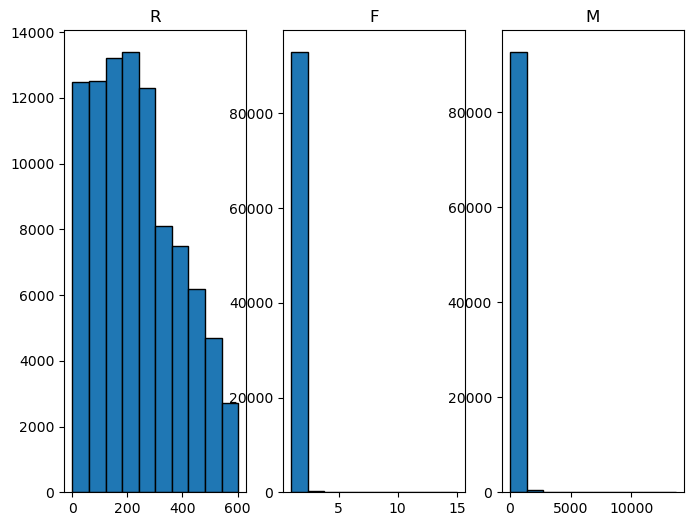

In [11]:
fig = plt.figure(figsize = (8,6),dpi=100)
(ax1,ax2,ax3) = fig.subplots(1,3)
ax1.hist(df_rfm['RECENCY'], edgecolor='k',rwidth=1.0)
ax2.hist(df_rfm['FREQUENCY'], edgecolor='k',rwidth=1.0)
ax3.hist(df_rfm['MONETARY'], edgecolor='k',rwidth=1.0)

ax1.set_title('R')
ax2.set_title('F')
ax3.set_title('M')
